# TP — Les $k$ plus proches voisins : choisir un modèle sans se tromper

**Cours d'apprentissage supervisé — Chapitre 1 : Introduction**
Mohammed SEDKI — Université Paris-Saclay

---

**Objectifs.** Mettre en pratique les notions du chapitre sur des données biomédicales réelles :

1. constater que l'erreur d'entraînement est trompeuse ;
2. observer le compromis biais–variance à travers le choix de $k$ ;
3. choisir $k$ par **validation croisée**, sans jamais toucher à l'échantillon de test ;
4. comprendre le rôle de la standardisation et des **fuites d'information** ;
5. passer d'un classifieur à une **décision médicale** (sensibilité, spécificité, coûts) ;
6. observer le **fléau de la dimension** ;
7. traiter un problème de **régression**.

**Durée indicative :** 3 h. Les parties marquées ★ sont facultatives (pour aller plus loin).

**Données.** Deux jeux de données biomédicaux fournis avec `scikit-learn` (aucun téléchargement nécessaire) :
le diagnostic du cancer du sein (classification) et la progression du diabète (régression).

**Mode d'emploi.** Les cellules contenant `...` ou `# À COMPLÉTER` sont à compléter.
Les questions appellent une réponse rédigée dans la cellule « Votre réponse » qui suit.

## 0. Mise en route

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold,
                                     cross_val_score, GridSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import confusion_matrix, mean_squared_error, r2_score
from sklearn.feature_selection import SelectKBest, f_classif

RANDOM_STATE = 0          # pour que tout le monde obtienne les mêmes résultats
plt.rcParams["figure.figsize"] = (7, 4)

## 1. Les données : diagnostic du cancer du sein (≈ 15 min)

Le jeu de données *Wisconsin Diagnostic Breast Cancer* décrit **569 tumeurs du sein**.
Pour chacune, un prélèvement par aspiration à l'aiguille fine a été photographié au microscope.
Sur l'image, on a mesuré 10 caractéristiques des noyaux cellulaires (rayon, texture, périmètre, aire,
régularité du contour, compacité, concavité, points concaves, symétrie, dimension fractale),
résumées de 3 façons (moyenne, erreur standard, pire valeur) : **$p = 30$ variables**.

La sortie est le diagnostic : tumeur **maligne** ou **bénigne**.

⚠️ Dans `scikit-learn`, la cible vaut 0 pour « maligne » et 1 pour « bénigne ». On la recode pour suivre la
convention médicale : **$y = 1$ pour maligne** (la classe « positive » est la maladie).

In [2]:
donnees = load_breast_cancer(as_frame=True)
X = donnees.data                 # tableau 569 x 30
y = 1 - donnees.target           # 1 = maligne, 0 = bénigne

print("Dimensions de X :", X.shape)
print("Effectifs par classe :", y.value_counts().to_dict())

Dimensions de X : (569, 30)
Effectifs par classe : {0: 357, 1: 212}

**Question 1.1.** Combien de tumeurs sont malignes ? Quel taux d'erreur obtiendrait un classifieur
qui répond toujours « bénigne », sans regarder $x$ ? Ce chiffre servira de **référence** : un modèle utile
doit faire nettement mieux.

In [3]:
print("Proportion de tumeurs malignes :", round(y.mean(), 3))

Proportion de tumeurs malignes : 0.373

> **Réponse.** 212 tumeurs sur 569 sont malignes, soit **37,3 %**. Un classifieur qui répond toujours « bénigne »
> se trompe exactement sur les tumeurs malignes : son taux d'erreur est de **37,3 %**.

**Question 1.2.** Observez les ordres de grandeur de quelques variables. Les $k$-ppv utilisent la
distance euclidienne $\|x - x'\|$ : quelle variable va dominer le calcul des distances ? Qu'en concluez-vous ?

In [4]:
X.describe().T.loc[["mean radius", "mean area", "mean smoothness", "worst area"],
                   ["mean", "std", "min", "max"]].round(3)

,mean,std,min,max
mean radius,14.127,3.524,6.981,28.110
mean area,654.889,351.914,143.500,2501.000
mean smoothness,0.096,0.014,0.053,0.163
worst area,880.583,569.357,185.200,4254.000


> **Réponse.** L'aire moyenne vaut environ 655 (écart-type 352), alors que la régularité du contour (*smoothness*)
> vaut environ 0,1 (écart-type 0,014). Dans une distance euclidienne, une différence d'aire de 100 pèse
> des milliers de fois plus qu'une différence de régularité : **les variables d'aire décident à elles seules
> qui sont les voisins**. Il faut donc **standardiser** les variables (centrer et réduire) pour qu'elles
> comptent toutes à égalité. On vérifiera l'effet de ce choix dans la partie 6.

## 2. Le piège de l'erreur d'entraînement (≈ 20 min)

On met de côté **25 % des données comme échantillon de test**. Ce test ne servira qu'à l'évaluation finale.
L'option `stratify=y` garde la même proportion de tumeurs malignes dans les deux échantillons.

In [5]:
X_app, X_test, y_app, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

print("Apprentissage :", X_app.shape, "  Test :", X_test.shape)

def taux_erreur(modele, X, y):
    # Proportion de prédictions fausses (perte 0-1 moyenne).
    return np.mean(modele.predict(X) != y)

Apprentissage : (426, 30)   Test : (143, 30)

### 2.1 Le classifieur « par cœur »

On programme le classifieur du cours : il **mémorise** les couples $(x_i, y_i)$ d'apprentissage ;
face à un $x$ déjà vu, il renvoie le $y_i$ mémorisé, sinon il répond 0 (bénigne).

**Question 2.1.** Complétez la classe, puis calculez ses erreurs d'entraînement et de test.

In [6]:
class ClassifieurParCoeur:
    def fit(self, X, y):
        # dictionnaire : profil x (converti en tuple) -> classe y
        self.memoire = {tuple(x): yi for x, yi in zip(np.asarray(X), np.asarray(y))}
        return self

    def predict(self, X):
        # classe mémorisée si x a déjà été vu, 0 sinon
        return np.array([self.memoire.get(tuple(x), 0) for x in np.asarray(X)])

par_coeur = ClassifieurParCoeur().fit(X_app, y_app)
print("Erreur d'entraînement :", round(taux_erreur(par_coeur, X_app, y_app), 3))
print("Erreur de test        :", round(taux_erreur(par_coeur, X_test, y_test), 3))

Erreur d'entraînement : 0.0
Erreur de test        : 0.371

### 2.2 Le plus proche voisin

On utilise maintenant `KNeighborsClassifier(n_neighbors=1)`. On l'enchaîne avec une standardisation grâce à
`make_pipeline` : le *pipeline* calcule les moyennes et écarts-types **sur les données d'apprentissage**
puis les applique aux nouvelles données.

**Question 2.2.** Calculez les erreurs d'entraînement et de test du 1-ppv. Pourquoi les deux classifieurs
ont-ils une erreur d'entraînement nulle ? Pourquoi leurs erreurs de test sont-elles si différentes ?

In [7]:
ppv1 = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1))
ppv1.fit(X_app, y_app)
print("Erreur d'entraînement :", round(taux_erreur(ppv1, X_app, y_app), 3))
print("Erreur de test        :", round(taux_erreur(ppv1, X_test, y_test), 3))

Erreur d'entraînement : 0.0
Erreur de test        : 0.063

> **Réponse.** Sur l'échantillon d'apprentissage, chaque $x_i$ est son propre plus proche voisin (distance nulle) :
> le 1-ppv redonne $y_i$, exactement comme le classifieur par cœur. Les deux ont donc une erreur
> d'entraînement **nulle**.
> 
> En test, aucun nouveau profil ne coïncide exactement avec un profil déjà vu (30 mesures continues) :
> le classifieur par cœur répond toujours 0 et se trompe sur toutes les tumeurs malignes, soit **37,1 %**
> d'erreur (la proportion de malignes dans le test), comme le classifieur naïf de la question 1.1.
> Le 1-ppv, lui, **généralise par proximité** : il prédit la classe du patient le plus ressemblant, d'où
> **6,3 %** d'erreur seulement.
> 
> **À retenir :** une erreur d'entraînement nulle ne dit rien de la qualité d'un modèle.

## 3. Influence de $k$ : la courbe en U (≈ 20 min)

**Question 3.1.** Pour $k = 1, \ldots, 60$, ajustez un $k$-ppv (avec standardisation) et stockez ses erreurs
d'entraînement et de test. Le code du graphique est fourni.

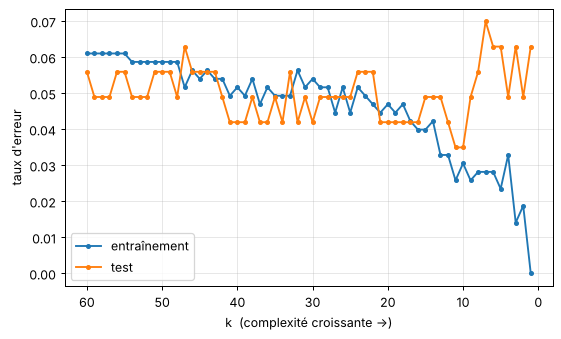

k minimisant l'erreur de test : 10  erreur : 0.035

In [8]:
valeurs_k = np.arange(1, 61)
err_app, err_test = [], []
for k in valeurs_k:
    modele = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    modele.fit(X_app, y_app)
    err_app.append(taux_erreur(modele, X_app, y_app))
    err_test.append(taux_erreur(modele, X_test, y_test))

plt.plot(valeurs_k, err_app, "o-", ms=3, label="entraînement")
plt.plot(valeurs_k, err_test, "o-", ms=3, label="test")
plt.gca().invert_xaxis()          # complexité croissante vers la droite
plt.xlabel("k  (complexité croissante →)")
plt.ylabel("taux d'erreur")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

k_test = valeurs_k[np.argmin(err_test)]
print("k minimisant l'erreur de test :", k_test, " erreur :", round(min(err_test), 3))

**Question 3.2.** Décrivez les deux courbes. Où se situent le surapprentissage et le sous-apprentissage ?

**Question 3.3.** Un collègue propose de publier : « avec $k = 10$, notre méthode n'a que 3,5 % d'erreur ».
Qu'en pensez-vous ?

> **Réponse.** **3.2.** L'erreur d'entraînement augmente avec $k$ (elle vaut 0 pour $k = 1$) : plus $k$ est petit, plus
> le modèle « colle » aux données d'apprentissage. L'erreur de test est plus élevée pour $k$ très petit
> (surapprentissage : variance forte, le modèle suit le bruit) et remonte pour $k$ grand
> (sous-apprentissage : biais fort, les voisins deviennent trop éloignés). Elle est minimale pour un $k$
> intermédiaire. La courbe est bruitée car le test ne contient que 143 patients : une erreur de plus ou de
> moins change le taux de 0,7 point.
> 
> **3.3.** Ce chiffre est **trop optimiste** : $k = 10$ a été choisi *en regardant l'échantillon de test*.
> On a retenu la valeur la plus favorable parmi 60, en partie par chance. Le test a servi à la fois à choisir
> et à évaluer : il n'est plus indépendant du modèle. Il faut choisir $k$ **sans** le test (parties 4 et 5).

## 4. Un seul découpage ne suffit pas (≈ 15 min)

Et si l'on avait tiré un autre échantillon de test ? On répète le découpage apprentissage/test avec
30 graines aléatoires différentes. Pour chacune, on note le $k$ qui minimise l'erreur de test, et l'erreur
de test obtenue avec $k = 5$.

**Question 4.1.** Complétez la boucle, puis commentez les deux graphiques.

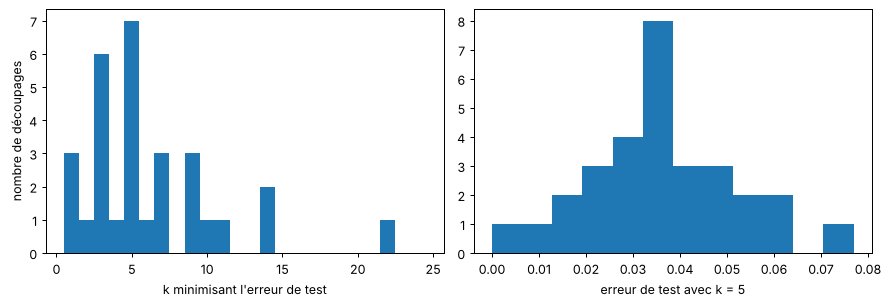

k choisis : [1, 1, 1, 2, 3, 3, 3, 3, 3, 3, 4, 5, 5, 5, 5, 5, 5, 5, 6, 7, 7, 7, 9, 9, 9, 10, 11, 14, 14, 22]
Erreur de test pour k = 5 : de 0.0 à 0.077

In [9]:
meilleurs_k, err_k5 = [], []
for graine in range(30):
    Xa, Xt, ya, yt = train_test_split(X, y, test_size=0.25, stratify=y, random_state=graine)
    erreurs = []
    for k in valeurs_k:
        modele = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(Xa, ya)
        erreurs.append(taux_erreur(modele, Xt, yt))
    meilleurs_k.append(int(valeurs_k[np.argmin(erreurs)]))
    err_k5.append(erreurs[4])                    # k = 5 est en position 4

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(meilleurs_k, bins=np.arange(0.5, 25.5, 1))
axes[0].set_xlabel("k minimisant l'erreur de test"); axes[0].set_ylabel("nombre de découpages")
axes[1].hist(err_k5, bins=12)
axes[1].set_xlabel("erreur de test avec k = 5")
plt.tight_layout(); plt.show()

print("k choisis :", sorted(meilleurs_k))
print("Erreur de test pour k = 5 : de", round(min(err_k5), 3), "à", round(max(err_k5), 3))

> **Réponse.** Selon le découpage, le « meilleur » $k$ varie de 1 à 22, et l'erreur de test d'un même modèle ($k = 5$)
> varie de 0 % à 7,7 %. Avec un seul découpage, **le choix de $k$ et l'erreur annoncée dépendent largement
> du hasard**. Il faut une procédure qui utilise toutes les données d'apprentissage et moyenne plusieurs
> découpages : la validation croisée.

## 5. Choisir $k$ par validation croisée (≈ 35 min)

Rappel du cours : on découpe l'échantillon d'apprentissage en $V$ blocs. Chaque bloc sert à tour de rôle de
bloc de validation ; le modèle est ajusté sur les $V - 1$ autres. L'erreur de validation croisée $\mathrm{CV}(k)$
est la moyenne des erreurs sur les blocs de validation.

**Le test reste de côté pendant toute cette partie.**

### 5.1 Programmer la validation croisée

`StratifiedKFold` fournit les indices des blocs (en gardant la proportion de malignes dans chaque bloc).

**Question 5.1.** Complétez la fonction `erreur_cv`.

In [10]:
def erreur_cv(k, X, y, V=5):
    blocs = StratifiedKFold(n_splits=V, shuffle=True, random_state=RANDOM_STATE)
    erreurs = []
    for idx_app, idx_val in blocs.split(X, y):
        modele = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
        modele.fit(X.iloc[idx_app], y.iloc[idx_app])                    # sans le bloc v
        erreurs.append(taux_erreur(modele, X.iloc[idx_val], y.iloc[idx_val]))  # sur le bloc v
    return np.mean(erreurs)

print("CV(1) =", round(erreur_cv(1, X_app, y_app), 3))

CV(1) = 0.035

### 5.2 La courbe $\mathrm{CV}(k)$

**Question 5.2.** Calculez $\mathrm{CV}(k)$ pour $k = 1, \ldots, 60$ et déterminez $\hat k = \arg\min_k \mathrm{CV}(k)$.

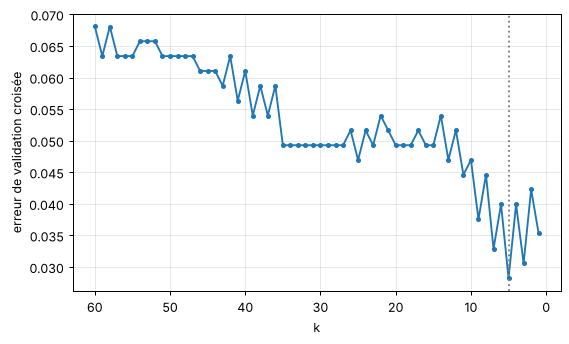

k choisi par validation croisée : 5   CV = 0.028

In [11]:
err_cv = [erreur_cv(k, X_app, y_app) for k in valeurs_k]
k_chapeau = valeurs_k[np.argmin(err_cv)]

plt.plot(valeurs_k, err_cv, "o-", ms=3)
plt.axvline(k_chapeau, ls=":", color="gray")
plt.gca().invert_xaxis()
plt.xlabel("k"); plt.ylabel("erreur de validation croisée"); plt.grid(alpha=0.3)
plt.show()
print("k choisi par validation croisée :", k_chapeau, "  CV =", round(min(err_cv), 3))

### 5.3 La même chose avec `scikit-learn`

`cross_val_score` calcule les scores sur les blocs (par défaut le taux de bonnes réponses, donc
erreur $= 1 -$ score). `GridSearchCV` fait toute la boucle sur $k$ et **réajuste automatiquement** le modèle
retenu sur tout l'échantillon d'apprentissage.

**Question 5.3.** Vérifiez que vous retrouvez la même erreur et le même $\hat k$.

In [12]:
blocs = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scores = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k_chapeau)),
                         X_app, y_app, cv=blocs)
print("cross_val_score : CV =", round(1 - scores.mean(), 3))

grille = {"kneighborsclassifier__n_neighbors": valeurs_k}
recherche = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()), grille, cv=blocs)
recherche.fit(X_app, y_app)
print("GridSearchCV    : k =", recherche.best_params_["kneighborsclassifier__n_neighbors"],
      " CV =", round(1 - recherche.best_score_, 3))

cross_val_score : CV = 0.028
GridSearchCV    : k = 5  CV = 0.028

### 5.4 Évaluation finale, une seule fois

**Question 5.4.** Évaluez le modèle retenu (`recherche`, déjà réajusté) sur l'échantillon de test.
L'erreur de test est-elle égale à l'erreur de validation croisée ? Pourquoi ?
*Indication :* l'écart-type d'une proportion d'erreurs $\hat p$ estimée sur $m$ individus est environ
$\sqrt{\hat p(1 - \hat p)/m}$.

In [13]:
err_finale = taux_erreur(recherche, X_test, y_test)
m = len(y_test)
ecart_type = np.sqrt(err_finale * (1 - err_finale) / m)
print("Erreur de test :", round(err_finale, 3), " (", int(round(err_finale * m)), "erreurs sur", m, ")")
print("Écart-type approximatif :", round(ecart_type, 3))

Erreur de test : 0.063  ( 9 erreurs sur 143 )
Écart-type approximatif : 0.02

> **Réponse.** La validation croisée choisit $\hat k = 5$ avec $\mathrm{CV} = 2{,}8\,\%$ ; l'erreur de test est de
> **6,3 %** (9 erreurs sur 143). L'écart s'explique par deux raisons :
> 
> * l'erreur de test est elle-même **aléatoire** : avec 143 patients, son écart-type est d'environ 2 points,
>   soit un intervalle de confiance approximatif de $6{,}3 \pm 4$ % ;
> * $\mathrm{CV}(\hat k)$ est le **minimum** de 60 erreurs de validation croisée : elle est légèrement optimiste.
> 
> C'est bien l'erreur de test qu'on annonce, avec son incertitude : environ **6 % d'erreur (± 4 %)**.

## 6. Standardiser ou non ? (≈ 15 min)

**Question 6.1.** Calculez la courbe $\mathrm{CV}(k)$ **sans** standardisation et comparez-la à celle de la partie 5.

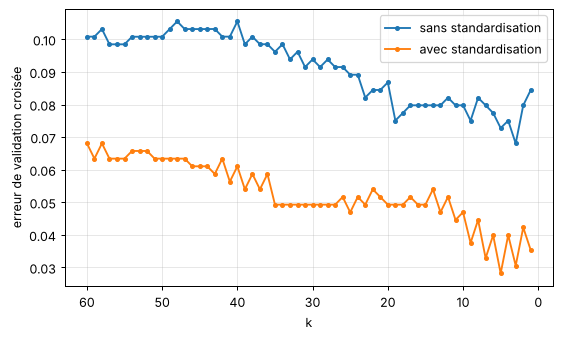

Meilleure CV sans standardisation : 0.068
Meilleure CV avec standardisation : 0.028

In [14]:
err_cv_brut = [1 - cross_val_score(KNeighborsClassifier(n_neighbors=k), X_app, y_app, cv=blocs).mean()
               for k in valeurs_k]

plt.plot(valeurs_k, err_cv_brut, "o-", ms=3, label="sans standardisation")
plt.plot(valeurs_k, err_cv, "o-", ms=3, label="avec standardisation")
plt.gca().invert_xaxis()
plt.xlabel("k"); plt.ylabel("erreur de validation croisée"); plt.legend(); plt.grid(alpha=0.3)
plt.show()
print("Meilleure CV sans standardisation :", round(min(err_cv_brut), 3))
print("Meilleure CV avec standardisation :", round(min(err_cv), 3))

**Question 6.2.** Pourquoi la standardisation est-elle placée **dans** le pipeline plutôt qu'appliquée
une fois pour toutes à `X` avant le découpage ?

> **Réponse.** **6.1.** Sans standardisation, la meilleure erreur est d'environ **6,8 %**, contre **2,8 %** avec : elle est
> plus que doublée. Les distances sont dominées par les variables d'aire (question 1.2) ; les autres mesures,
> pourtant informatives, sont ignorées.
> 
> **6.2.** Dans le pipeline, les moyennes et écarts-types sont recalculés **sur les seules données
> d'apprentissage** de chaque bloc, puis appliqués au bloc de validation (ou au test). Standardiser `X` en
> entier avant le découpage utiliserait des informations sur les données de validation et de test :
> c'est une **fuite d'information**. Ici l'effet est faible, mais la partie 9 montre qu'une fuite peut être
> catastrophique.

## 7. Du vote à la décision médicale (≈ 20 min)

### 7.1 Matrice de confusion

On note « positif » une tumeur prédite maligne. Deux indicateurs sont utilisés en médecine :

* **sensibilité** $= \dfrac{VP}{VP + FN}$ : proportion de tumeurs malignes détectées ;
* **spécificité** $= \dfrac{VN}{VN + FP}$ : proportion de tumeurs bénignes reconnues comme telles.

**Question 7.1.** Calculez la matrice de confusion du modèle retenu sur le test, puis sa sensibilité et sa
spécificité.

In [15]:
def bilan(y_vrai, y_pred):
    vn, fp, fn, vp = confusion_matrix(y_vrai, y_pred).ravel()
    print(f"VN = {vn}, FP = {fp}, FN = {fn}, VP = {vp}")
    print(f"sensibilité = {vp / (vp + fn):.3f}   spécificité = {vn / (vn + fp):.3f}")

bilan(y_test, recherche.predict(X_test))

VN = 84, FP = 6, FN = 3, VP = 50
sensibilité = 0.943   spécificité = 0.933

### 7.2 Changer le seuil selon les coûts

`predict_proba` renvoie, pour chaque patient, la proportion de tumeurs malignes parmi ses $k$ voisins :
c'est l'estimation $\hat\eta_k(x)$ de $\eta(x) = \P(Y = 1 \mid X = x)$. Par défaut, on prédit « maligne » si
$\hat\eta_k(x) > 1/2$.

Le cours montre qu'avec des coûts asymétriques, le seuil optimal est $\dfrac{c_{FP}}{c_{FP} + c_{FN}}$.

**Question 7.2.** On estime que rater un cancer (faux négatif) coûte 5 fois plus cher qu'une biopsie inutile
(faux positif) : $c_{FN} = 5$, $c_{FP} = 1$. Calculez le seuil, appliquez-le et comparez les deux bilans.

In [16]:
eta_chapeau = recherche.predict_proba(X_test)[:, 1]      # proportion de voisins malins
print("Valeurs prises par eta_chapeau :", np.unique(eta_chapeau))

c_FN, c_FP = 5, 1
seuil = c_FP / (c_FP + c_FN)
print("Seuil :", round(seuil, 3))

print("\n--- seuil 1/2 ---");  bilan(y_test, (eta_chapeau > 0.5).astype(int))
print("\n--- seuil 1/6 ---");  bilan(y_test, (eta_chapeau > seuil).astype(int))

Valeurs prises par eta_chapeau : [0.  0.2 0.4 0.6 0.8 1. ]
Seuil : 0.167

--- seuil 1/2 ---
VN = 84, FP = 6, FN = 3, VP = 50
sensibilité = 0.943   spécificité = 0.933

--- seuil 1/6 ---
VN = 76, FP = 14, FN = 1, VP = 52
sensibilité = 0.981   spécificité = 0.844

> **Réponse.** **7.1.** Au seuil 1/2 : 3 faux négatifs et 6 faux positifs ; sensibilité **94,3 %**, spécificité **93,3 %**.
> 
> **7.2.** Le seuil vaut $1/(1 + 5) = 1/6$. Avec $k = 5$, $\hat\eta_k$ ne prend que les valeurs
> $0, 0{,}2, \ldots, 1$ : on prédit « maligne » **dès qu'un seul des 5 voisins est malin**.
> On ne rate plus qu'un cancer (sensibilité **98,1 %**) au prix de 14 faux positifs (spécificité **84,4 %**).
> 
> Pour un dépistage, où un cancer manqué est grave et une biopsie inutile acceptable, le seuil bas est
> préférable ; le choix des coûts relève d'un **dialogue avec les cliniciens**, pas de l'algorithme.
> Remarque : en toute rigueur, le seuil devrait lui aussi être choisi et vérifié sans utiliser le test.

## 8. ★ Le fléau de la dimension (≈ 20 min)

On ajoute aux 30 variables $q$ variables de **pur bruit** (tirées au hasard, sans lien avec le diagnostic),
comme dans une étude où l'on mesure beaucoup de choses inutiles. On compare l'erreur de validation croisée
du $k$-ppv ($k$ choisi par `GridSearchCV`) à celle d'une **régression logistique** : un modèle linéaire pour la
classification, vu plus loin dans le cours, utilisé ici comme une boîte noire.

**Question 8.1.** Lancez la cellule et commentez.

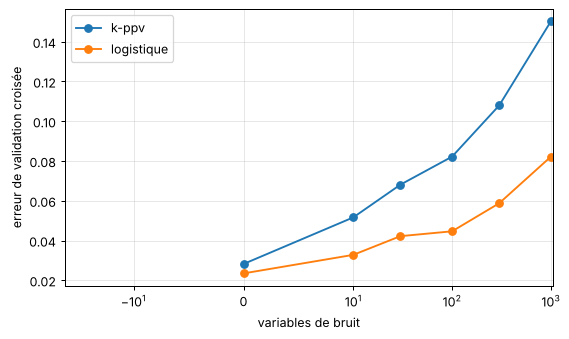

,k-ppv,logistique
variables de bruit,,
0,0.028,0.023
10,0.052,0.033
30,0.068,0.042
100,0.082,0.045
300,0.108,0.059
1000,0.150,0.082


In [17]:
generateur = np.random.default_rng(RANDOM_STATE)
grille_k = {"kneighborsclassifier__n_neighbors": np.arange(1, 61, 2)}
resultats = []
for q in [0, 10, 30, 100, 300, 1000]:
    bruit = generateur.standard_normal((len(X_app), q))
    X_bruite = np.hstack([X_app.values, bruit])
    kppv = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()), grille_k, cv=blocs)
    kppv.fit(X_bruite, y_app)
    logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
    err_logit = 1 - cross_val_score(logit, X_bruite, y_app, cv=blocs).mean()
    resultats.append({"variables de bruit": q, "k-ppv": 1 - kppv.best_score_, "logistique": err_logit})

resultats = pd.DataFrame(resultats).set_index("variables de bruit")
resultats.plot(marker="o")
plt.xscale("symlog", linthresh=10)         # échelle adaptée à q = 0, 10, ..., 1000
plt.ylabel("erreur de validation croisée"); plt.grid(alpha=0.3); plt.show()
resultats.round(3)

> **Réponse.** Avec les 30 vraies variables seulement, les deux méthodes sont proches (2,8 % et 2,3 % d'erreur). Quand on ajoute du
> bruit, l'erreur du $k$-ppv monte jusqu'à **15 %** (1000 variables de bruit), celle de la régression
> logistique jusqu'à environ 8 %.
> 
> Le $k$-ppv donne le **même poids à toutes les variables** dans la distance : les variables de bruit
> dominent et les « plus proches voisins » ne sont plus des patients réellement ressemblants
> (fléau de la dimension). La régression logistique **apprend un poids par variable** et peut donner des
> poids presque nuls aux variables inutiles : son pari (un effet linéaire de chaque variable) résiste mieux.
> Elle se dégrade tout de même quand $p$ dépasse $n$ (1030 variables pour 426 patients).

## 9. ★ Données omiques : la mauvaise façon de faire une validation croisée (≈ 15 min)

Situation typique en génomique : **$n = 50$ patients, $p = 5000$ gènes**. Ici, les « expressions de gènes » sont
du **pur bruit** et les classes sont tirées au hasard : aucune méthode ne peut faire mieux que **50 %**
d'erreur.

Une pratique répandue consiste à **sélectionner d'abord** les 100 gènes les plus liés à $y$ sur toutes
les données, puis à faire la validation croisée sur ces 100 gènes.

**Question 9.1.** Comparez cette « mauvaise » validation croisée à la « bonne », où la sélection est faite
**dans** le pipeline, donc recalculée dans chaque bloc. On répète l'expérience sur 20 jeux de données.

In [18]:
erreurs_mauvaise, erreurs_bonne = [], []
for rep in range(20):
    gen = np.random.default_rng(rep)
    X_omique = gen.standard_normal((50, 5000))          # 50 patients, 5000 gènes (bruit)
    y_omique = np.repeat([0, 1], 25)                      # classes sans lien avec X
    blocs_omique = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

    # Mauvaise façon : sélection sur TOUTES les données, puis validation croisée
    X_selection = SelectKBest(f_classif, k=100).fit_transform(X_omique, y_omique)
    erreurs_mauvaise.append(1 - cross_val_score(KNeighborsClassifier(n_neighbors=1),
                                                X_selection, y_omique, cv=blocs_omique).mean())

    # Bonne façon : la sélection fait partie du modèle
    modele = make_pipeline(SelectKBest(f_classif, k=100), KNeighborsClassifier(n_neighbors=1))
    erreurs_bonne.append(1 - cross_val_score(modele, X_omique, y_omique, cv=blocs_omique).mean())

print("Erreur CV, mauvaise façon :", round(np.mean(erreurs_mauvaise), 3))
print("Erreur CV, bonne façon    :", round(np.mean(erreurs_bonne), 3))

Erreur CV, mauvaise façon : 0.012
Erreur CV, bonne façon    : 0.537

> **Réponse.** La mauvaise façon annonce environ **1 %** d'erreur sur des données sans aucune information !
> La bonne façon donne environ **54 %**, compatible avec les 50 % attendus.
> 
> Parmi 5000 gènes de bruit, certains sont liés à $y$ **par hasard** dans cet échantillon. En les choisissant
> avec toutes les données, on a déjà regardé les classes des blocs de validation : ces derniers ne sont plus
> des « nouveaux patients ». **Toute étape qui utilise $y$ (sélection de variables, choix d'hyperparamètres…)
> doit être refaite à l'intérieur de chaque bloc**, ce que garantit un pipeline.

## 10. Régression : progression du diabète (≈ 25 min)

Le jeu de données *diabetes* décrit **442 patients diabétiques** : âge, sexe, indice de masse corporelle (`bmi`),
pression artérielle moyenne (`bp`) et 6 mesures sanguines (`s1` à `s6`). La sortie $y$ est une **mesure
quantitative de la progression de la maladie un an après**. Les variables sont déjà centrées et mises à
l'échelle par `scikit-learn`.

On utilise la perte quadratique : l'erreur est l'**erreur quadratique moyenne** (EQM).

In [19]:
Xd, yd = load_diabetes(return_X_y=True, as_frame=True)
Xd_app, Xd_test, yd_app, yd_test = train_test_split(Xd, yd, test_size=0.25, random_state=RANDOM_STATE)
print("Apprentissage :", Xd_app.shape, "  Test :", Xd_test.shape)
Xd.head()

Apprentissage : (331, 10)   Test : (111, 10)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


**Question 10.1.** Référence naïve : d'après le cours, quelle est la meilleure prédiction **constante**
pour la perte quadratique ? Calculez son EQM de test.

In [20]:
constante = yd_app.mean()
eqm_constante = mean_squared_error(yd_test, np.full(len(yd_test), constante))
print("Prédiction constante :", round(constante, 1), "  EQM de test :", round(eqm_constante, 1))

Prédiction constante : 151.9   EQM de test : 4965.1

**Question 10.2.** Choisissez $k$ par validation croisée à 5 blocs pour un `KNeighborsRegressor`
(`scoring="neg_mean_squared_error"` : `scikit-learn` maximise les scores, d'où le signe moins).
Tracez la courbe de validation croisée et calculez l'EQM de test du modèle retenu.

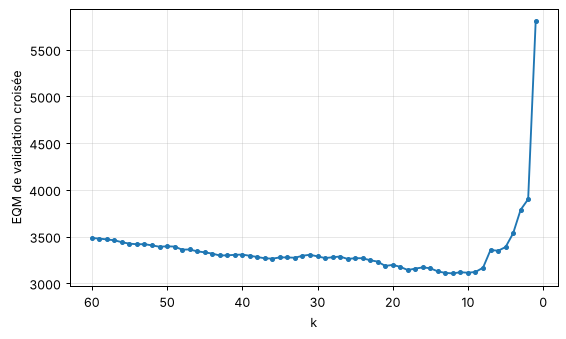

k = 12  EQM CV : 3106.0  EQM test : 3412.5

In [21]:
blocs_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grille_reg = {"kneighborsregressor__n_neighbors": valeurs_k}
kppv_reg = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsRegressor()), grille_reg,
                        cv=blocs_reg, scoring="neg_mean_squared_error")
kppv_reg.fit(Xd_app, yd_app)

plt.plot(valeurs_k, -kppv_reg.cv_results_["mean_test_score"], "o-", ms=3)
plt.gca().invert_xaxis()
plt.xlabel("k"); plt.ylabel("EQM de validation croisée"); plt.grid(alpha=0.3)
plt.show()

eqm_kppv = mean_squared_error(yd_test, kppv_reg.predict(Xd_test))
print("k =", kppv_reg.best_params_["kneighborsregressor__n_neighbors"],
      " EQM CV :", round(-kppv_reg.best_score_, 1), " EQM test :", round(eqm_kppv, 1))

**Question 10.3.** Comparez avec une **régression linéaire** (moindres carrés), puis complétez le tableau.
Le coefficient $R^2 = 1 - \text{EQM} / \text{variance de } y$ mesure la part de variabilité expliquée.
Quelle méthode retenir ici ? Est-ce en contradiction avec la partie 8 ?

In [22]:
lineaire = LinearRegression().fit(Xd_app, yd_app)
eqm_lineaire = mean_squared_error(yd_test, lineaire.predict(Xd_test))

bilan_reg = pd.DataFrame({
    "EQM de test": [eqm_constante, eqm_kppv, eqm_lineaire],
    "R2 de test": [r2_score(yd_test, np.full(len(yd_test), constante)),
                   r2_score(yd_test, kppv_reg.predict(Xd_test)),
                   r2_score(yd_test, lineaire.predict(Xd_test))]},
    index=["constante (moyenne)", f"k-ppv (k = {kppv_reg.best_params_['kneighborsregressor__n_neighbors']})",
           "régression linéaire"])
bilan_reg.round(3)

,EQM de test,R2 de test
constante (moyenne),4965.126,-0.000
k-ppv (k = 12),3412.537,0.313
régression linéaire,3180.160,0.359


> **Réponse.** **10.1.** La meilleure constante pour la perte quadratique est l'espérance de $Y$ (cours, preuve 1/2),
> estimée par la moyenne de l'échantillon d'apprentissage. Son EQM de test (≈ 4965) est proche de la variance
> de $y$ : c'est le niveau « on ne sait rien ».
> 
> **10.2.** La validation croisée retient $\hat k = 12$ ; l'EQM de test vaut environ 3413, soit un $R^2$
> d'environ 0,31.
> 
> **10.3.** La régression linéaire fait mieux (EQM ≈ 3180, $R^2 \approx 0{,}36$) et elle est plus simple à
> interpréter. Avec $n = 442$ patients et des effets à peu près linéaires, son pari est le bon.
> Ce n'est pas en contradiction avec la partie 8 : c'est le message du théorème *No Free Lunch*.
> **Aucune méthode ne gagne partout** ; on compare les candidats par validation croisée, et on réserve le
> test à l'évaluation finale. Notez enfin que même le meilleur modèle n'explique qu'un tiers de la
> variabilité : une grande part de l'erreur est irréductible avec ces 10 variables.

## Bilan : les bonnes pratiques

1. **Mettre de côté un échantillon de test** dès le début, et ne l'utiliser qu'une fois, à la fin.
2. **Ne jamais juger un modèle sur son erreur d'entraînement** (parties 2 et 3).
3. **Choisir les hyperparamètres** (ici $k$) **par validation croisée** sur l'échantillon d'apprentissage (partie 5).
4. **Mettre toute transformation dans le pipeline** : standardisation, sélection de variables… (parties 6 et 9).
5. **Toujours comparer à une référence naïve** (classe majoritaire, moyenne).
6. **Annoncer l'erreur avec son incertitude**, et **choisir le seuil selon les coûts** du problème (partie 7).
7. **Aucune méthode n'est la meilleure partout** : comparer plusieurs familles de modèles (parties 8 et 10).